In [1]:
import os, time, math, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU - enable it!")

PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
Device: cuda | Tesla T4


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 487kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.43MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.65MB/s]


60000 10000 torch.Size([1, 28, 28])


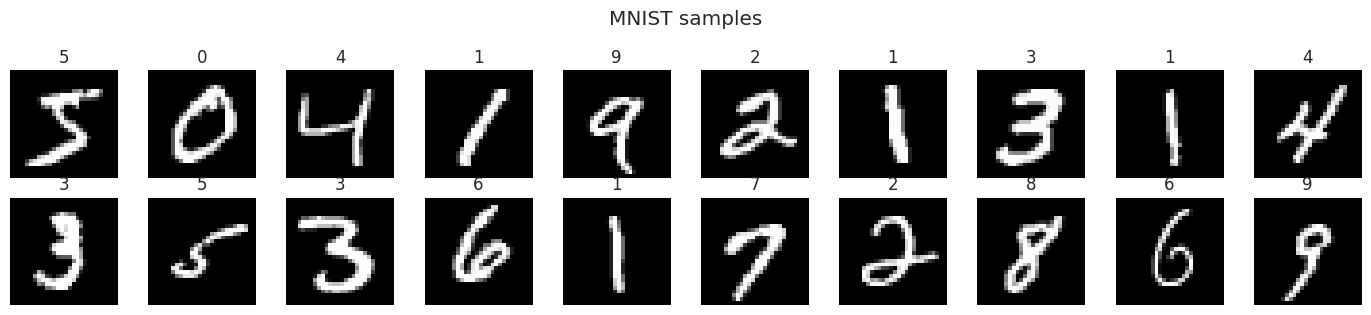

{0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}


In [2]:
MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
tf_mnist = transforms.Compose([transforms.ToTensor(),
                               transforms.Normalize((MNIST_MEAN,), (MNIST_STD,))])

train_ds = datasets.MNIST(root="data", train=True,  download=True, transform=tf_mnist)
test_ds  = datasets.MNIST(root="data", train=False, download=True, transform=tf_mnist)
print(len(train_ds), len(test_ds), train_ds[0][0].shape)

BS = 128
train_loader = DataLoader(train_ds, batch_size=BS,  shuffle=True,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=512, shuffle=False, num_workers=2, pin_memory=True)

# Quick EDA: sample images + class balance
raw = datasets.MNIST(root="data", train=True, download=False)
fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for k, a in enumerate(ax.ravel()):
    a.imshow(raw.data[k], cmap="gray"); a.set_title(int(raw.targets[k])); a.axis("off")
plt.suptitle("MNIST samples"); plt.tight_layout(); plt.show()
print(pd.Series(raw.targets.numpy()).value_counts().sort_index().to_dict())

In [3]:
RESULTS = {}   # name -> metrics, history, predictions

def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))

def sync():
    if device.type == "cuda": torch.cuda.synchronize()    # GPU runs asynchronously: needed for honest timing

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    total, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x)
        total += crit(out, y).item()
        ps.append(out.argmax(1).cpu()); ys.append(y.cpu())
    ys, ps = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return total / len(ys), accuracy_score(ys, ps), ys, ps

def fit_clf(name, model, train_loader, test_loader, epochs, lr=1e-3, weight_decay=0.0, optimizer="adam"):
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]     # skips frozen layers
    opt = (torch.optim.Adam(params, lr=lr, weight_decay=weight_decay) if optimizer == "adam"
           else torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay))
    crit = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    train_time = 0.0
    for ep in range(epochs):
        model.train(); sync(); t0 = time.time()
        tot, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad()
            out = model(x)
            loss = crit(out, y)
            loss.backward()
            opt.step()
            tot += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
        sync(); train_time += time.time() - t0           # evaluation time is NOT counted
        tl, ta, _, _ = evaluate(model, test_loader)
        hist["train_loss"].append(tot / n); hist["train_acc"].append(correct / n)
        hist["test_loss"].append(tl);       hist["test_acc"].append(ta)
        print(f"[{name}] epoch {ep+1:02d}/{epochs}  train loss {tot/n:.4f} acc {correct/n:.4f} | "
              f"test loss {tl:.4f} acc {ta:.4f}")
    tl, ta, ys, ps = evaluate(model, test_loader)
    RESULTS[name] = dict(acc=ta, f1=f1_score(ys, ps, average="macro"), loss=tl, loss_type="cross-entropy",
                         time=train_time, params=count_params(model), trainable=count_params(model, True),
                         hist=hist, ys=ys, ps=ps)
    print(f"[{name}] FINAL  acc {ta:.4f}  macro-F1 {RESULTS[name]['f1']:.4f}  train time {train_time:.1f}s")
    return model

def plot_curves(name):
    h = RESULTS[name]["hist"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["train_loss"], label="Train"); ax[0].plot(h["test_loss"], label="Test")
    ax[0].set_title(f"{name} - Loss / Epochs"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
    if h.get("train_acc"): ax[1].plot(h["train_acc"], label="Train")
    ax[1].plot(h["test_acc"], label="Test")
    ax[1].set_title(f"{name} - Accuracy / Epochs"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"curves_{name.replace(' ', '_')}.png", dpi=150); plt.show()

def plot_confusion(name):
    r = RESULTS[name]
    labels = [l for l in range(10)]
    cm = confusion_matrix(r["ys"], r["ps"], labels=labels)
    plt.figure(figsize=(6, 5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} - confusion matrix (test)"); plt.xlabel("Predicted"); plt.ylabel("True")
    plt.savefig(f"cm_{name.replace(' ', '_')}.png", dpi=150); plt.show()

**PART 1.1: CNN classifier (task 1)**

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 421834
[CNN] epoch 01/8  train loss 0.1753 acc 0.9466 | test loss 0.0498 acc 0.9828
[CNN] epoch 02/8  train loss 0.0642 acc 0.9808 | test loss 0.0402 acc 0.9862
[CNN] epoc

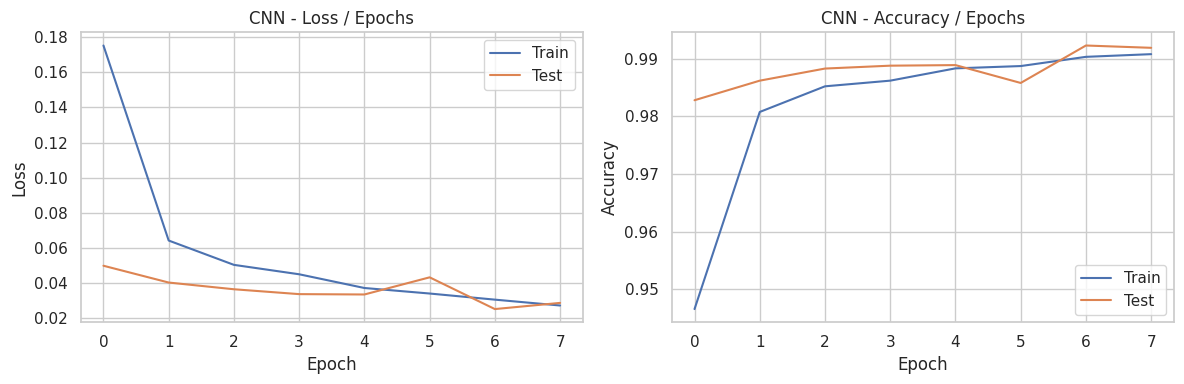

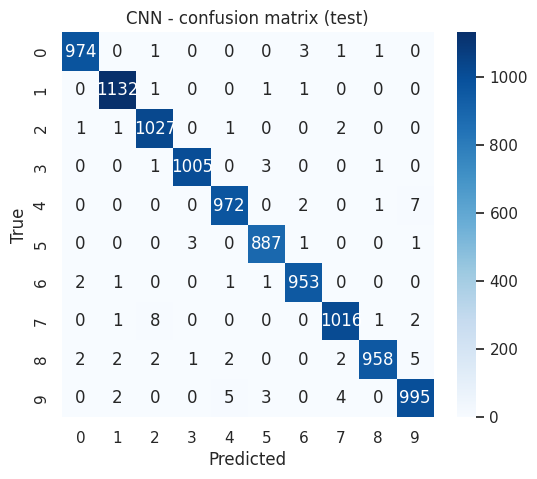

              precision    recall  f1-score   support

           0     0.9949    0.9939    0.9944       980
           1     0.9939    0.9974    0.9956      1135
           2     0.9875    0.9952    0.9913      1032
           3     0.9960    0.9950    0.9955      1010
           4     0.9908    0.9898    0.9903       982
           5     0.9911    0.9944    0.9927       892
           6     0.9927    0.9948    0.9937       958
           7     0.9912    0.9883    0.9898      1028
           8     0.9958    0.9836    0.9897       974
           9     0.9851    0.9861    0.9856      1009

    accuracy                         0.9919     10000
   macro avg     0.9919    0.9918    0.9919     10000
weighted avg     0.9919    0.9919    0.9919     10000



In [4]:
class CNN(nn.Module):
    def __init__(self, n_classes=10, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
cnn = CNN()
print(cnn); print("Parameters:", count_params(cnn))
cnn = fit_clf("CNN", cnn, train_loader, test_loader, epochs=8, lr=1e-3, weight_decay=1e-4, optimizer="adam")
plot_curves("CNN"); plot_confusion("CNN")
print(classification_report(RESULTS["CNN"]["ys"], RESULTS["CNN"]["ps"], digits=4))

**PART 1.2: Faster R-CNN (task 2)**

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 77.1MB/s]


Parameters: 18976354
[Faster R-CNN] epoch 1/3  train loss nan | test loss nan acc 0.0000
[Faster R-CNN] epoch 2/3  train loss nan | test loss nan acc 0.0000
[Faster R-CNN] epoch 3/3  train loss nan | test loss nan acc 0.0000
0.0 0.0 458.0s


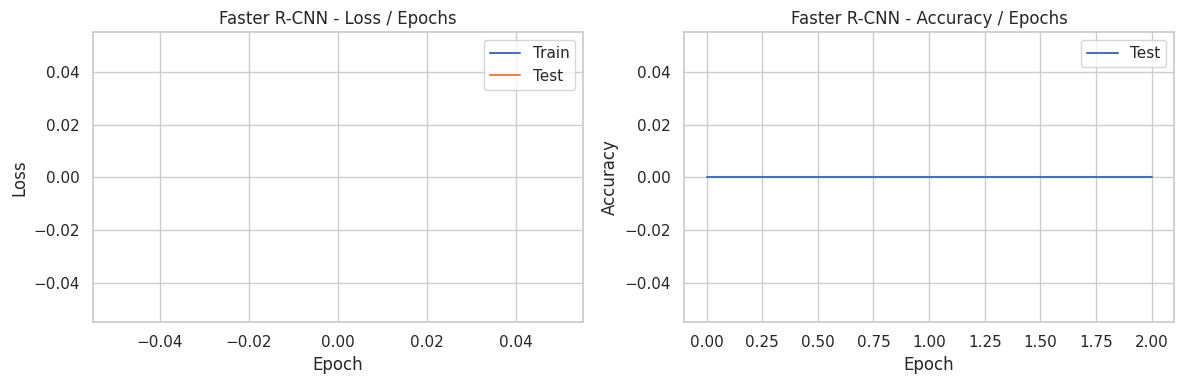

In [5]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models import MobileNet_V3_Large_Weights

class MNISTDet(Dataset):
    """MNIST as a detection dataset: one box + one label per image."""
    def __init__(self, train=True, n=None):
        ds = datasets.MNIST(root="data", train=train, download=True)
        idx = torch.randperm(len(ds), generator=torch.Generator().manual_seed(SEED))[:n]
        self.x, self.y = ds.data[idx], ds.targets[idx]
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        img = self.x[i].float() / 255.                               # (28, 28) in [0, 1]
        ys, xs = torch.where(img > 0.2)
        box = [0., 0., 28., 28.] if len(xs) == 0 else [xs.min().item(), ys.min().item(),
                                                        xs.max().item() + 1, ys.max().item() + 1]
        target = {"boxes": torch.tensor([box], dtype=torch.float32),
                  "labels": torch.tensor([int(self.y[i]) + 1], dtype=torch.int64)}   # 0 = background
        return img.unsqueeze(0).repeat(3, 1, 1), target              # 3 channels: the backbone expects RGB

def collate(batch): return tuple(zip(*batch))                        # detection batches are lists, not tensors

det_train = DataLoader(MNISTDet(True, 10000),  batch_size=32, shuffle=True,  collate_fn=collate, num_workers=2)
det_test  = DataLoader(MNISTDet(False, 2000), batch_size=64, shuffle=False, collate_fn=collate, num_workers=2)

set_seed()
frcnn = fasterrcnn_mobilenet_v3_large_320_fpn(
    weights=None, weights_backbone=MobileNet_V3_Large_Weights.IMAGENET1K_V1,
    num_classes=11, min_size=128, max_size=128).to(device)
print("Parameters:", count_params(frcnn))

def to_dev(imgs, tgts):
    return [i.to(device) for i in imgs], [{k: v.to(device) for k, v in t.items()} for t in tgts]

@torch.no_grad()
def det_eval(model, loader):
    # (1) loss: torchvision only returns losses in train mode (its BatchNorm layers are frozen, so this is safe)
    model.train(); tot, n = 0.0, 0
    for imgs, tgts in loader:
        imgs, tgts = to_dev(imgs, tgts)
        tot += sum(model(imgs, tgts).values()).item() * len(imgs); n += len(imgs)
    # (2) predictions: top-scoring detection per image
    model.eval(); ys, ps = [], []
    for imgs, tgts in loader:
        outs = model([i.to(device) for i in imgs])
        for o, t in zip(outs, tgts):
            ys.append(t["labels"].item() - 1)
            ps.append(o["labels"][o["scores"].argmax()].item() - 1 if len(o["scores"]) else -1)   # -1 = nothing detected
    ys, ps = np.array(ys), np.array(ps)
    return tot / n, accuracy_score(ys, ps), ys, ps

EPOCHS_DET = 3
params = [p for p in frcnn.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=5e-4)
hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
train_time = 0.0
for ep in range(EPOCHS_DET):
    frcnn.train(); sync(); t0 = time.time(); tot, n = 0.0, 0
    for imgs, tgts in det_train:
        imgs, tgts = to_dev(imgs, tgts)
        loss = sum(frcnn(imgs, tgts).values())        # RPN + box regression + classification losses
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(imgs); n += len(imgs)
    sync(); train_time += time.time() - t0
    tl, ta, _, _ = det_eval(frcnn, det_test)
    hist["train_loss"].append(tot / n); hist["test_loss"].append(tl); hist["test_acc"].append(ta)
    print(f"[Faster R-CNN] epoch {ep+1}/{EPOCHS_DET}  train loss {tot/n:.4f} | test loss {tl:.4f} acc {ta:.4f}")

tl, ta, ys, ps = det_eval(frcnn, det_test)
RESULTS["Faster R-CNN"] = dict(acc=ta, f1=f1_score(ys, ps, average="macro", labels=list(range(10))), loss=tl,
                               loss_type="detection loss (not comparable)", time=train_time,
                               params=count_params(frcnn), trainable=count_params(frcnn, True),
                               hist=hist, ys=ys, ps=ps)
print(RESULTS["Faster R-CNN"]["acc"], RESULTS["Faster R-CNN"]["f1"], f"{train_time:.1f}s")
plot_curves("Faster R-CNN")

**PART 1.3: Compare CNN and Faster R-CNN (task 3)**

              Params (M)  Trainable (M)  Test accuracy  Macro F1  Test loss  \
Model                                                                         
CNN               0.4218         0.4218         0.9919    0.9919     0.0286   
Faster R-CNN     18.9764        18.9175         0.0000    0.0000        NaN   

                                    Loss type  Train time (s)  
Model                                                          
CNN                             cross-entropy        115.2941  
Faster R-CNN  detection loss (not comparable)        457.9877  


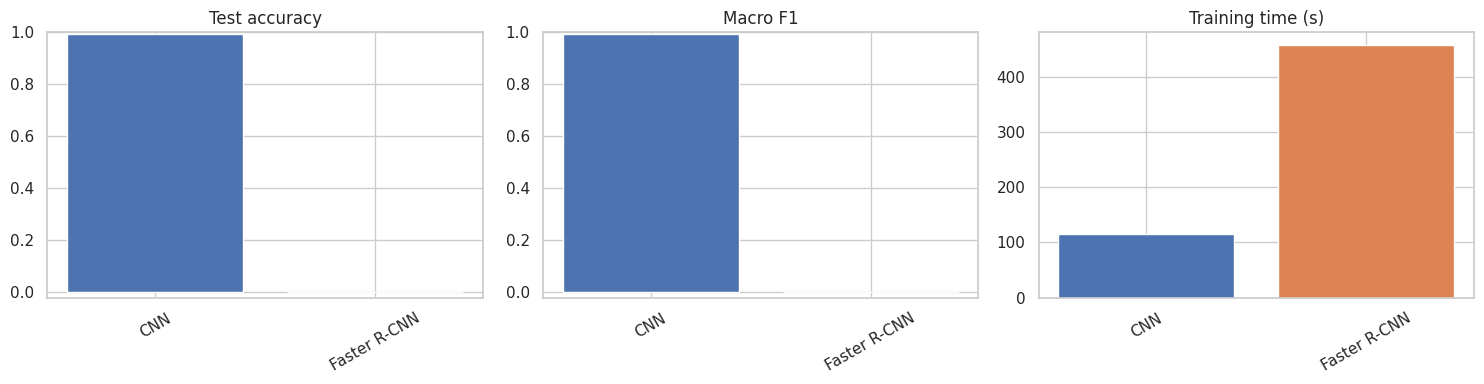

In [6]:
def comparison_table(names=None):
    names = names or list(RESULTS)
    rows = [{"Model": k, "Params (M)": RESULTS[k]["params"] / 1e6, "Trainable (M)": RESULTS[k]["trainable"] / 1e6,
             "Test accuracy": RESULTS[k]["acc"], "Macro F1": RESULTS[k]["f1"], "Test loss": RESULTS[k]["loss"],
             "Loss type": RESULTS[k]["loss_type"], "Train time (s)": RESULTS[k]["time"]} for k in names]
    return pd.DataFrame(rows).set_index("Model").round(4)

def comparison_plots(names=None):
    names = names or list(RESULTS)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for a, (key, title) in zip(ax, [("acc", "Test accuracy"), ("f1", "Macro F1"), ("time", "Training time (s)")]):
        vals = [RESULTS[k][key] for k in names]
        a.bar(names, vals, color=sns.color_palette("deep", len(names)))
        a.set_title(title); a.tick_params(axis="x", rotation=30)
        if key != "time": a.set_ylim(min(vals) - 0.02, 1.0)
    plt.tight_layout(); plt.savefig("comparison.png", dpi=150); plt.show()

print(comparison_table(["CNN", "Faster R-CNN"])); comparison_plots(["CNN", "Faster R-CNN"])

**PART 1.4: Fine-tune VGG16 and AlexNet (task 4)**

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 128MB/s]


AlexNet total params: 57044810 | trainable: 54575114
[AlexNet (fine-tuned)] epoch 01/2  train loss 0.6898 acc 0.7961 | test loss 0.2916 acc 0.9040
[AlexNet (fine-tuned)] epoch 02/2  train loss 0.3500 acc 0.8886 | test loss 0.2549 acc 0.9221
[AlexNet (fine-tuned)] FINAL  acc 0.9221  macro-F1 0.9211  train time 21.9s


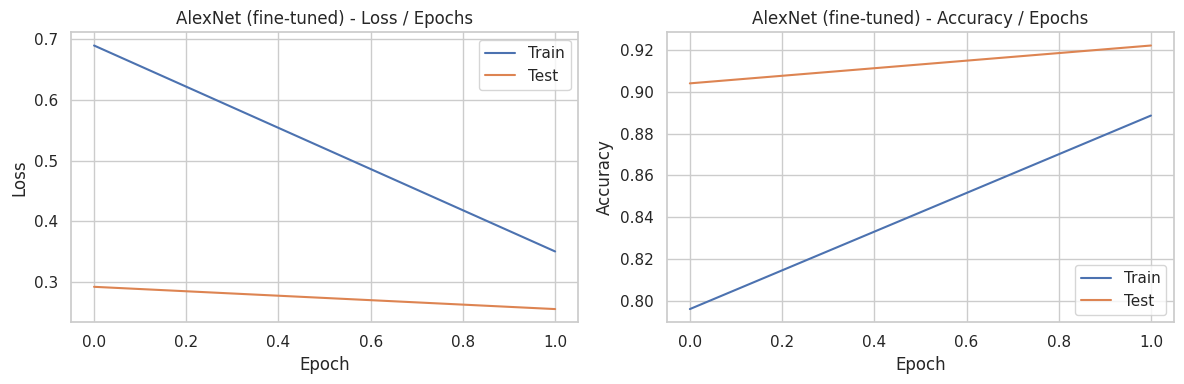

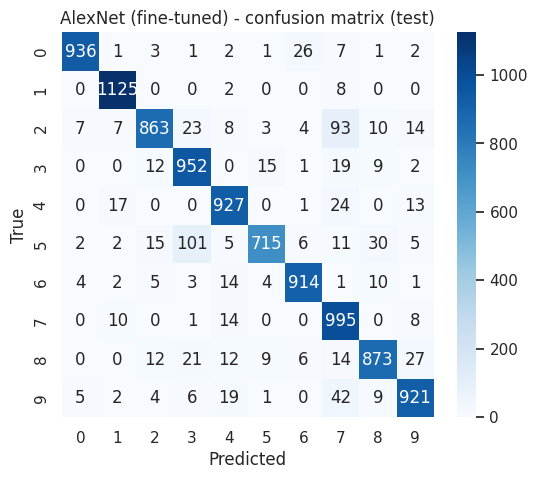

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 70.0MB/s]


VGG16 total params: 134301514 | trainable: 119586826
[VGG16 (fine-tuned)] epoch 01/2  train loss 0.5123 acc 0.8403 | test loss 0.2571 acc 0.9211
[VGG16 (fine-tuned)] epoch 02/2  train loss 0.2703 acc 0.9214 | test loss 0.2080 acc 0.9412
[VGG16 (fine-tuned)] FINAL  acc 0.9412  macro-F1 0.9408  train time 42.0s


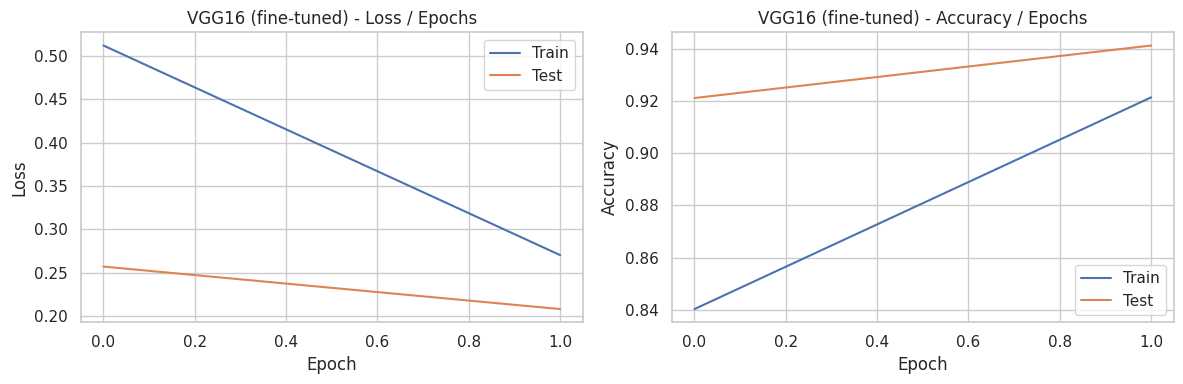

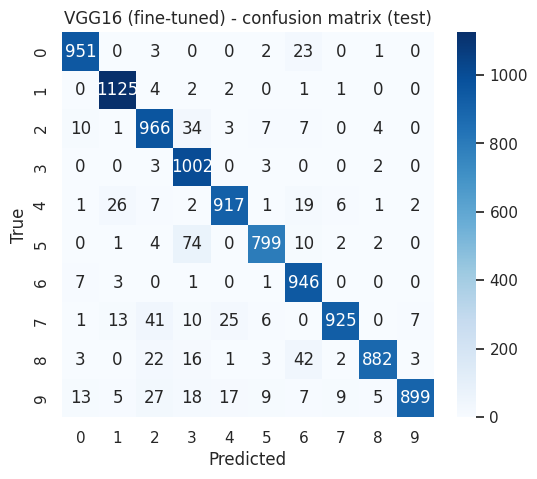

                      Params (M)  Trainable (M)  Test accuracy  Macro F1  \
Model                                                                      
CNN                       0.4218         0.4218         0.9919    0.9919   
Faster R-CNN             18.9764        18.9175         0.0000    0.0000   
AlexNet (fine-tuned)     57.0448        54.5751         0.9221    0.9211   
VGG16 (fine-tuned)      134.3015       119.5868         0.9412    0.9408   

                      Test loss                        Loss type  \
Model                                                              
CNN                      0.0286                    cross-entropy   
Faster R-CNN                NaN  detection loss (not comparable)   
AlexNet (fine-tuned)     0.2549                    cross-entropy   
VGG16 (fine-tuned)       0.2080                    cross-entropy   

                      Train time (s)  
Model                                 
CNN                         115.2941  
Faster R-CNN     

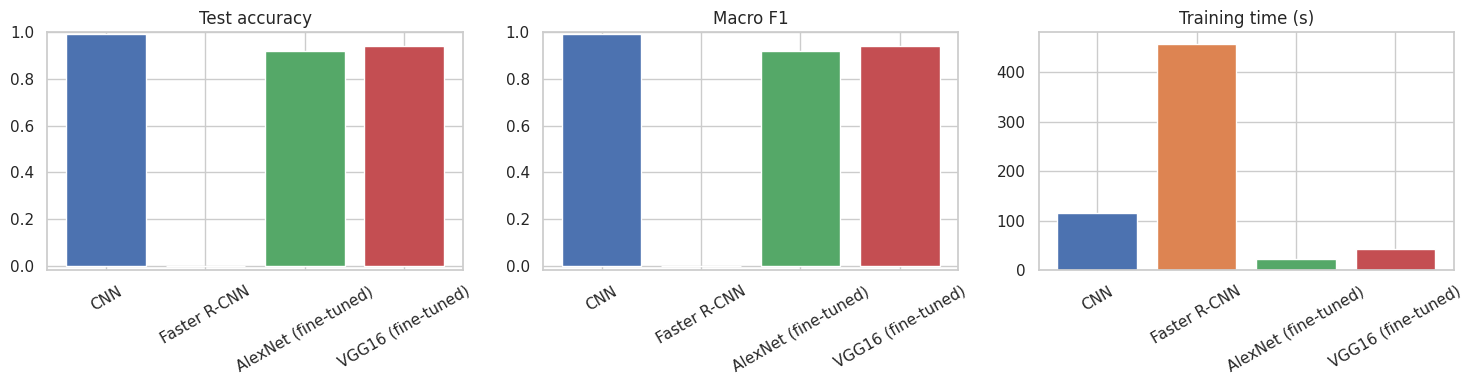

In [7]:
tf_tl = transforms.Compose([transforms.Resize(64), transforms.Grayscale(num_output_channels=3),
                            transforms.ToTensor(),
                            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
tl_train = datasets.MNIST(root="data", train=True,  download=False, transform=tf_tl)
tl_test  = datasets.MNIST(root="data", train=False, download=False, transform=tf_tl)
idx = torch.randperm(len(tl_train), generator=torch.Generator().manual_seed(SEED))[:20000]   # 20k images for speed
tl_train_loader = DataLoader(Subset(tl_train, idx), batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
tl_test_loader  = DataLoader(tl_test,               batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

def build_pretrained(arch, mode="classifier"):
    if arch == "AlexNet": m = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
    else:                 m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    if mode in ("head", "classifier"):
        for p in m.features.parameters(): p.requires_grad = False     # keep ImageNet features
    if mode == "head":
        for p in m.classifier.parameters(): p.requires_grad = False   # freeze the dense layers too
    m.classifier[6] = nn.Linear(4096, 10)                             # NEW output layer (1000 -> 10), always trainable
    return m

for arch in ["AlexNet", "VGG16"]:
    set_seed()
    m = build_pretrained(arch, mode="classifier")
    print(arch, "total params:", count_params(m), "| trainable:", count_params(m, True))
    fit_clf(f"{arch} (fine-tuned)", m, tl_train_loader, tl_test_loader, epochs=2, lr=1e-3, optimizer="adam")
    plot_curves(f"{arch} (fine-tuned)"); plot_confusion(f"{arch} (fine-tuned)")
    del m; torch.cuda.empty_cache()

print(comparison_table()); comparison_plots()

**PART 2: Vision Transformer from scratch**

Parameters: 201866
torch.Size([2, 10])
[ViT] epoch 01/15  train loss 0.7338 acc 0.7415 | test loss 0.2122 acc 0.9360
[ViT] epoch 02/15  train loss 0.1654 acc 0.9496 | test loss 0.1200 acc 0.9625
[ViT] epoch 03/15  train loss 0.1160 acc 0.9635 | test loss 0.1222 acc 0.9609
[ViT] epoch 04/15  train loss 0.0926 acc 0.9711 | test loss 0.1080 acc 0.9663
[ViT] epoch 05/15  train loss 0.0762 acc 0.9755 | test loss 0.0858 acc 0.9717
[ViT] epoch 06/15  train loss 0.0658 acc 0.9792 | test loss 0.0744 acc 0.9762
[ViT] epoch 07/15  train loss 0.0572 acc 0.9817 | test loss 0.0617 acc 0.9804
[ViT] epoch 08/15  train loss 0.0550 acc 0.9826 | test loss 0.0607 acc 0.9803
[ViT] epoch 09/15  train loss 0.0471 acc 0.9847 | test loss 0.0673 acc 0.9794
[ViT] epoch 10/15  train loss 0.0451 acc 0.9855 | test loss 0.0666 acc 0.9787
[ViT] epoch 11/15  train loss 0.0382 acc 0.9872 | test loss 0.0562 acc 0.9830
[ViT] epoch 12/15  train loss 0.0394 acc 0.9868 | test loss 0.0683 acc 0.9799
[ViT] epoch 13/15  train 

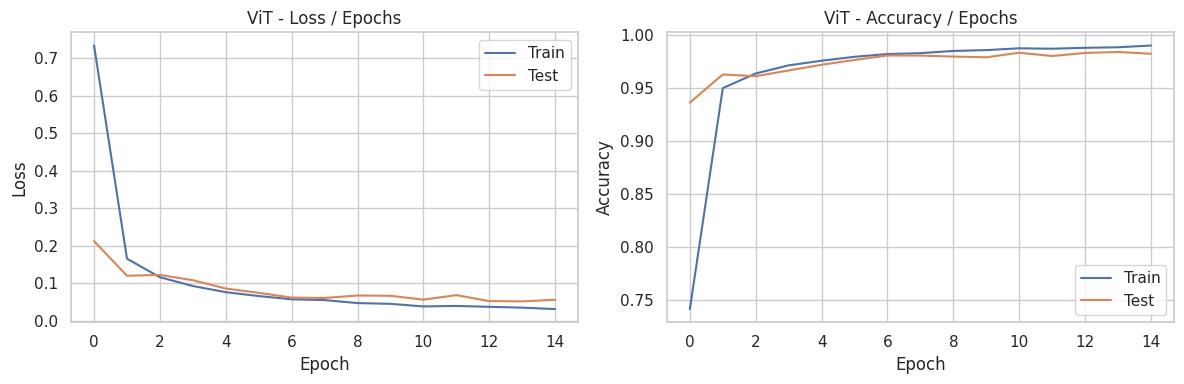

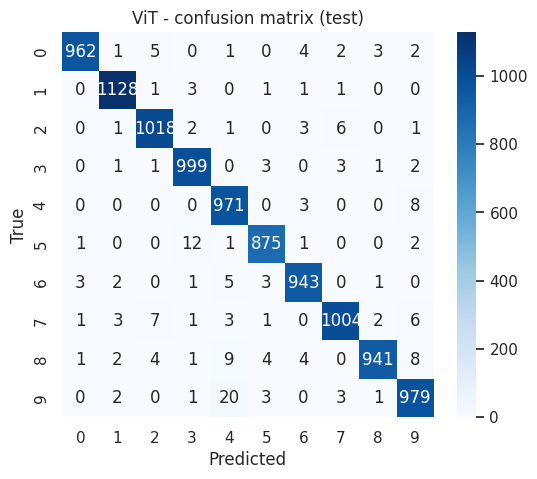

In [8]:
import math

def patchify(images, n_patches):
    B, C, H, W = images.shape
    p = H // n_patches                                              # patch size: 28 // 7 = 4
    x = images.unfold(2, p, p).unfold(3, p, p)                      # (B, C, 7, 7, 4, 4)
    x = x.contiguous().view(B, C, n_patches * n_patches, p * p)     # (B, C, 49, 16)
    return x.permute(0, 2, 1, 3).reshape(B, n_patches * n_patches, C * p * p)   # (B, 49, 16)

def sinusoidal(n_tokens, d):
    pos = torch.arange(n_tokens).unsqueeze(1).float()
    i = torch.arange(d).unsqueeze(0)
    angle = pos / (10000 ** ((2 * (i // 2)).float() / d))
    return torch.where(i % 2 == 0, torch.sin(angle), torch.cos(angle))        # (n_tokens, d)

class MSA(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        assert d % heads == 0, "d must be divisible by the number of heads"
        self.h, self.dk = heads, d // heads
        self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, self.dk).permute(2, 0, 3, 1, 4)   # each (B, h, N, dk)
        att = ((q @ k.transpose(-2, -1)) / math.sqrt(self.dk)).softmax(dim=-1)           # (B, h, N, N)
        return self.proj((att @ v).transpose(1, 2).reshape(B, N, D))

class Block(nn.Module):
    def __init__(self, d, heads, mlp_ratio=4):
        super().__init__()
        self.n1, self.att = nn.LayerNorm(d), MSA(d, heads)
        self.n2, self.mlp = nn.LayerNorm(d), nn.Sequential(nn.Linear(d, mlp_ratio * d), nn.GELU(), nn.Linear(mlp_ratio * d, d))
    def forward(self, x):
        x = x + self.att(self.n1(x))
        return x + self.mlp(self.n2(x))

class ViT(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, d=64, heads=4, blocks=4, n_out=10):
        super().__init__()
        C, H, W = chw
        self.n_patches = n_patches
        self.embed = nn.Linear(C * (H // n_patches) * (W // n_patches), d)
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        self.register_buffer("pos", sinusoidal(n_patches ** 2 + 1, d).unsqueeze(0))   # (1, 50, d), not trained
        self.blocks = nn.Sequential(*[Block(d, heads) for _ in range(blocks)])
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, n_out)
    def forward(self, x):
        t = self.embed(patchify(x, self.n_patches))                    # (B, 49, d)
        t = torch.cat([self.cls.expand(len(t), -1, -1), t], dim=1) + self.pos   # (B, 50, d)
        return self.head(self.norm(self.blocks(t)[:, 0]))              # class token -> 10 scores

set_seed()
vit = ViT(d=64, heads=4, blocks=4)
print("Parameters:", count_params(vit))
print(vit(torch.randn(2, 1, 28, 28)).shape)       # sanity check -> torch.Size([2, 10])
vit = fit_clf("ViT", vit, train_loader, test_loader, epochs=15, lr=1e-3, weight_decay=1e-4, optimizer="adam")
plot_curves("ViT"); plot_confusion("ViT")

                      Params (M)  Trainable (M)  Test accuracy  Macro F1  \
Model                                                                      
CNN                       0.4218         0.4218         0.9919    0.9919   
Faster R-CNN             18.9764        18.9175         0.0000    0.0000   
AlexNet (fine-tuned)     57.0448        54.5751         0.9221    0.9211   
VGG16 (fine-tuned)      134.3015       119.5868         0.9412    0.9408   
ViT                       0.2019         0.2019         0.9820    0.9819   

                      Test loss                        Loss type  \
Model                                                              
CNN                      0.0286                    cross-entropy   
Faster R-CNN                NaN  detection loss (not comparable)   
AlexNet (fine-tuned)     0.2549                    cross-entropy   
VGG16 (fine-tuned)       0.2080                    cross-entropy   
ViT                      0.0560                    cross-en

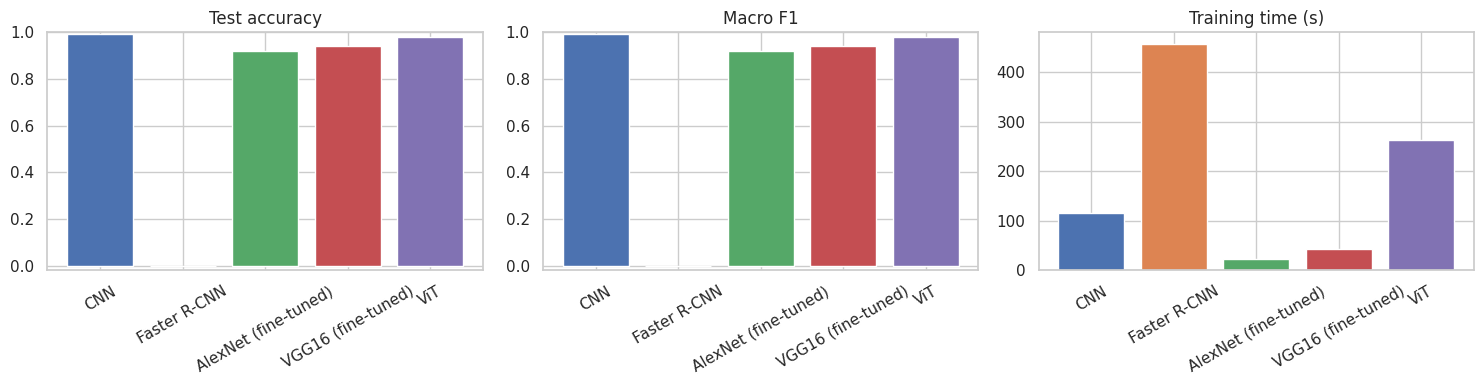

In [9]:
print(comparison_table()); comparison_plots()
comparison_table().to_csv("final_comparison.csv")